# 01 — exp020: kiến trúc và regularization của mlp

người thực hiện: như

  ngày: 18/11/2026 

 trạng thái: new

ba lượt train mới bằng CLI , notebook thực thi các ô đọc dữ liệu, kết quả và hình thật

R01 là kết quả chính, R02/R03 kiểm tra tái lập cùng seed. không chọn lượt có điểm cao nhất


## 02 — câu hỏi nghiên cứu

mạng nhỏ hơn và alpha lớn hơn có cải thiện macro f1 / balanced accuracy trên người được giữ lại làm test so với exp010 không?

giả thuyết: lưới [16] / [32,16] với alpha 0.01 / 0.1 có thể hạn chế khớp quá sát train

giữ learning rate 0.001, max_iter 200, seed 42, dữ liệu, scaling và không ROS

đây là khảo sát kết hợp kiến trúc và regularization




In [3]:
%pip install PyYAML

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 03 — dữ liệu và môi trường


In [4]:
from pathlib import Path
import sys, json
root = next(p for p in [Path.cwd(), Path.cwd()/'wesad-stress-detection', *Path.cwd().parents] if (p/'src/wesad').is_dir())
sys.path.insert(0,str(root/'src'))
sys.path.insert(0,str(root/'scripts'))
import pandas as pd
from wesad.utils import read_json, read_config, file_hash, environment
from wesad.data import SUBJECTS, load_feature_table
package = root/'experiments/04_additional/EXP-020'
run = package/'results'
config = read_config(run/'config.yaml')
frame, features = load_feature_table(root/config['features'],root/config['schema'],SUBJECTS)
assert len(frame)==6189 and len(features)==68
assert file_hash(root/config['features'])==config['feature_sha256']
print('ngày chạy:',read_json(run/'notebook_provenance.json')['date'])
print('python notebook:',sys.version.split()[0])
print('python thực thi:',sys.executable)
print('dữ liệu:',config['features'])
print('sha256:',config['feature_sha256'])
print('số dòng:',len(frame),'| feature:',len(features),'| subject:',frame.subject_id.nunique())
print(pd.crosstab(frame.subject_id,frame.label_original).to_string())
print('môi trường train:',read_json(run/'environment.json'))


ngày chạy: 18/11/2026
python notebook: 3.12.14
python thực thi: d:\venvs\wesad312\Scripts\python.exe
dữ liệu: data/features/g2_physiological68_group15_20261107/all_subjects.csv
sha256: 2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba
số dòng: 6189 | feature: 68 | subject: 15
label_original    1    2   3
subject_id                  
S10             226  135  65
S11             227  126  64
S13             226  124  67
S14             219  126  65
S15             226  128  64
S16             226  125  64
S17             226  135  65
S2              219  113  63
S3              218  118  65
S4              222  117  65
S5              230  119  65
S6              226  121  65
S7              228  118  65
S8              224  124  64
S9              227  119  65
môi trường train: {'python': '3.12.14 | packaged by conda-forge | (main, Sep  2 2026, 23:18:20) [MSC v.1944 64 bit (AMD64)]', 'packages': {'numpy': '2.5.4', 'pandas': '3.1.0', 'PyYAML': '6.0.3', 'scipy': '1.18.1', '

## 04 — protocol

15 outer LOSO folds cho từng task, train 14 người và test 1 người

multiclass: 1 baseline, 2 stress, 3 amusement

binary: stress=1, còn lại=0 

median imputation và StandardScaler fit bên trong từng train fold , không ROS

outer test không dùng chọn tham số hoặc dừng epoch

đánh giá bằng mean và sd mẫu (ddof=1) theo 15 người 


In [5]:
verification=read_json(run/'verification.json')
assert verification['status']=='passed' and verification['outer_folds']==30
print(json.dumps(verification,ensure_ascii=False,indent=2))
print('split ví dụ multiclass/S4:')
print(json.dumps(read_json(run/'splits.json')['multiclass/mlp/S4'],ensure_ascii=False,indent=2))


{
  "status": "passed",
  "experiment": "EXP-020",
  "outer_folds": 30,
  "predictions": 12378,
  "candidates_per_outer": 4,
  "inner_folds": 3,
  "checks": [
    "data hash",
    "checkpoint hashes",
    "subject leakage",
    "new grid",
    "candidate identity and inner winner",
    "predictions and metrics",
    "loss",
    "mean and sample sd"
  ]
}
split ví dụ multiclass/S4:
{
  "outer_train_subjects": [
    "S10",
    "S11",
    "S13",
    "S14",
    "S15",
    "S16",
    "S17",
    "S2",
    "S3",
    "S5",
    "S6",
    "S7",
    "S8",
    "S9"
  ],
  "outer_test_subjects": [
    "S4"
  ],
  "inner_splits": [
    {
      "train_subjects": [
        "S10",
        "S13",
        "S15",
        "S16",
        "S2",
        "S3",
        "S5",
        "S7",
        "S8",
        "S9"
      ],
      "validation_subjects": [
        "S11",
        "S14",
        "S17",
        "S6"
      ]
    },
    {
      "train_subjects": [
        "S11",
        "S13",
        "S14",
        "

## 05 — cấu hình đã dùng


In [6]:
from sklearn.model_selection import ParameterGrid
print('seed:',config['seed'],'| balance:',config['balance'])
print('tham số cố định:',config['model_params'])
for i,candidate in enumerate(ParameterGrid(config['search_spaces']['mlp']),1):
    print('ứng viên',i,candidate)
print('tham số được chọn theo inner CV:')
print(pd.read_csv(run/'convergence.csv')[['task','subject_id','hidden_sizes','alpha','n_iter']].to_string(index=False))


seed: 42 | balance: False
tham số cố định: {'mlp': {'max_iter': 200, 'early_stopping': False, 'learning_rate_init': 0.001}}
ứng viên 1 {'model__alpha': 0.01, 'model__hidden_layer_sizes': [16]}
ứng viên 2 {'model__alpha': 0.01, 'model__hidden_layer_sizes': [32, 16]}
ứng viên 3 {'model__alpha': 0.1, 'model__hidden_layer_sizes': [16]}
ứng viên 4 {'model__alpha': 0.1, 'model__hidden_layer_sizes': [32, 16]}
tham số được chọn theo inner CV:
      task subject_id hidden_sizes  alpha  n_iter
multiclass         S2     [32, 16]   0.01      44
multiclass         S3     [32, 16]   0.01      44
multiclass         S4     [32, 16]   0.01      44
multiclass         S5     [32, 16]   0.01      44
multiclass         S6     [32, 16]   0.01      46
multiclass         S7     [32, 16]   0.01      46
multiclass         S8     [32, 16]   0.01      44
multiclass         S9     [32, 16]   0.01      45
multiclass        S10     [32, 16]   0.01      44
multiclass        S11     [32, 16]   0.01      45
multiclass 

## 06 — thực thi

ba lượt train thật đã chạy và được lưu trong results cùng repeatability/R02, R03



In [7]:
import subprocess
RUN_TRAIN=False
if RUN_TRAIN:
    assert environment()==read_json(run/'environment.json'), 'chọn đúng môi trường train trước'
    subprocess.run([sys.executable,'-X','utf8','-u',str(root/'scripts/exp020_train.py')],cwd=root,check=True)
else:
    print('chỉ đọc kết quả đã lưu; không huấn luyện lại')
print('nguồn R01:',read_json(run/'notebook_provenance.json')['command'])
print(pd.read_csv(run/'repeatability.csv').to_string(index=False))


chỉ đọc kết quả đã lưu; không huấn luyện lại
nguồn R01: C:\Users\LEGION\Desktop\github\Machine-learning\wesad-stress-detection\.venv-g1\Scripts\python.exe scripts/exp020_train.py
exp_chung      run_id       date       task  seed  outer_folds  prediction_differences  macro_f1_mean  macro_f1_std  balanced_accuracy_mean  balanced_accuracy_std                                                source_run
  EXP-020 EXP-020-R01 18/11/2026 multiclass    42           30                       0       0.621062      0.114969                0.660917               0.103798          outputs/exp020_mlp_nested_20261118_222536_918478
  EXP-020 EXP-020-R01 18/11/2026     binary    42           30                       0       0.816369      0.175437                0.835633               0.164323          outputs/exp020_mlp_nested_20261118_222536_918478
  EXP-020 EXP-020-R02 18/11/2026 multiclass    42           30                       0       0.621062      0.114969                0.660917               0.10

## 07 — kết quả thực tế


In [8]:
metrics=pd.read_csv(run/'verified_metrics_by_subject.csv')
assert len(metrics)==30
summary=metrics.groupby('task')[['macro_f1','balanced_accuracy']].agg(['mean','std'])
print(summary.to_string())
print();print('điểm từng subject:')
print(metrics[['task','subject_id','macro_f1','balanced_accuracy','warning_count']].to_string(index=False))
print();print('so sánh theo cặp với exp006 và exp010:')
print(pd.read_csv(run/'comparison_summary.csv').to_string(index=False))


            macro_f1           balanced_accuracy          
                mean       std              mean       std
task                                                      
binary      0.816369  0.175437          0.835633  0.164323
multiclass  0.621062  0.114969          0.660917  0.103798

điểm từng subject:
      task subject_id  macro_f1  balanced_accuracy  warning_count
multiclass         S2  0.408480           0.513662              0
multiclass         S3  0.685835           0.767066              0
multiclass         S4  0.616822           0.652422              0
multiclass         S5  0.711363           0.728763              0
multiclass         S6  0.830666           0.800000              0
multiclass         S7  0.765154           0.792173              0
multiclass         S8  0.626780           0.648714              0
multiclass         S9  0.476451           0.473389              0
multiclass        S10  0.602810           0.635693              0
multiclass        S11  0.

## 08.hình minh họa

nguồn: metrics, inner CV, dự đoán và loss của R01

train/test lấy từ refit bổ sung giữ nguyên tham số

 trục train/test là subject, không phải epoch




exp010_vs_exp020.png


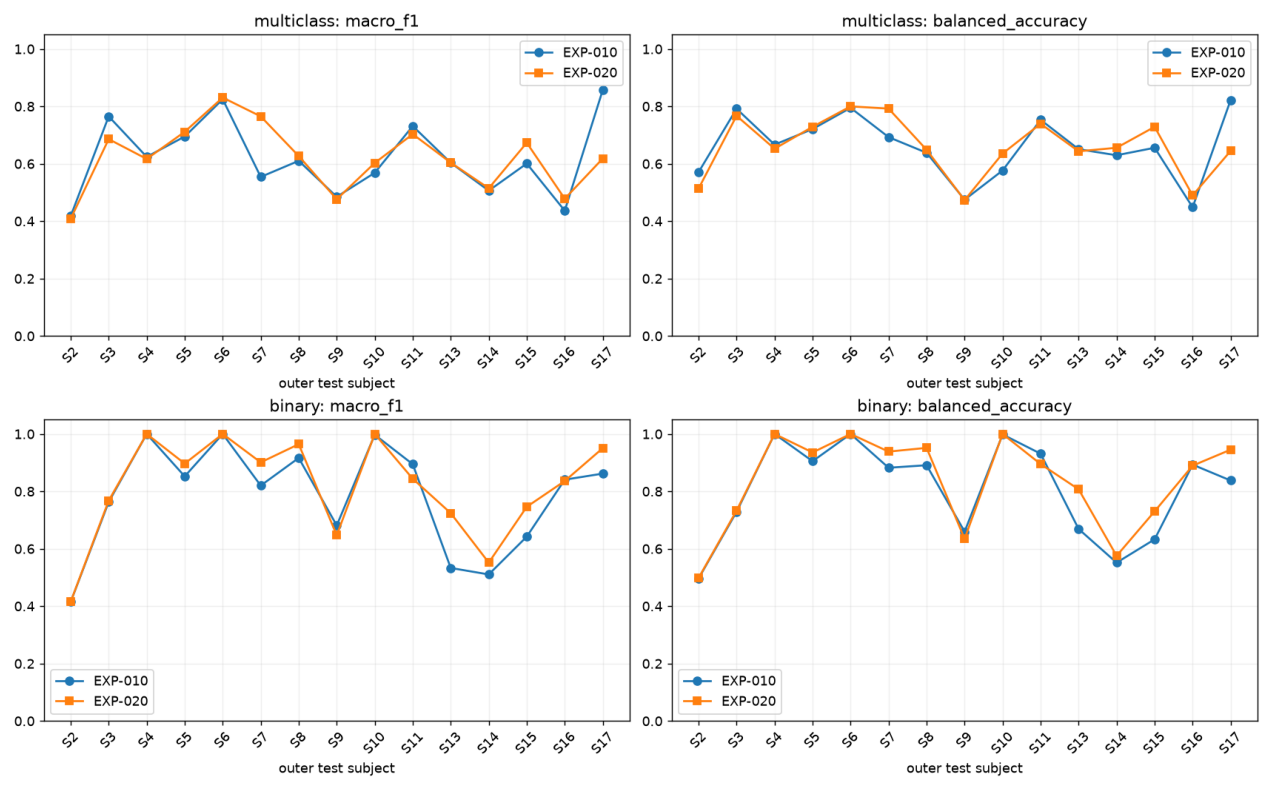

train_vs_test.png


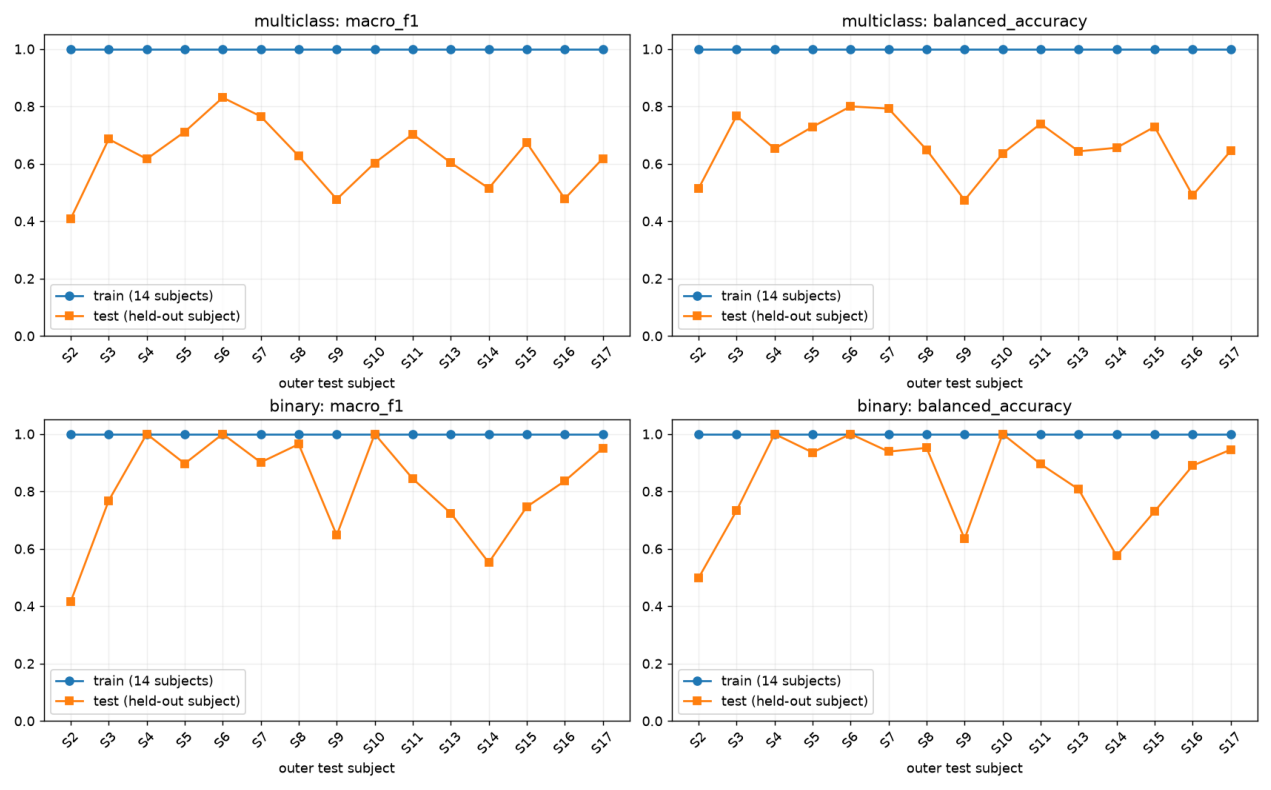

train_loss.png


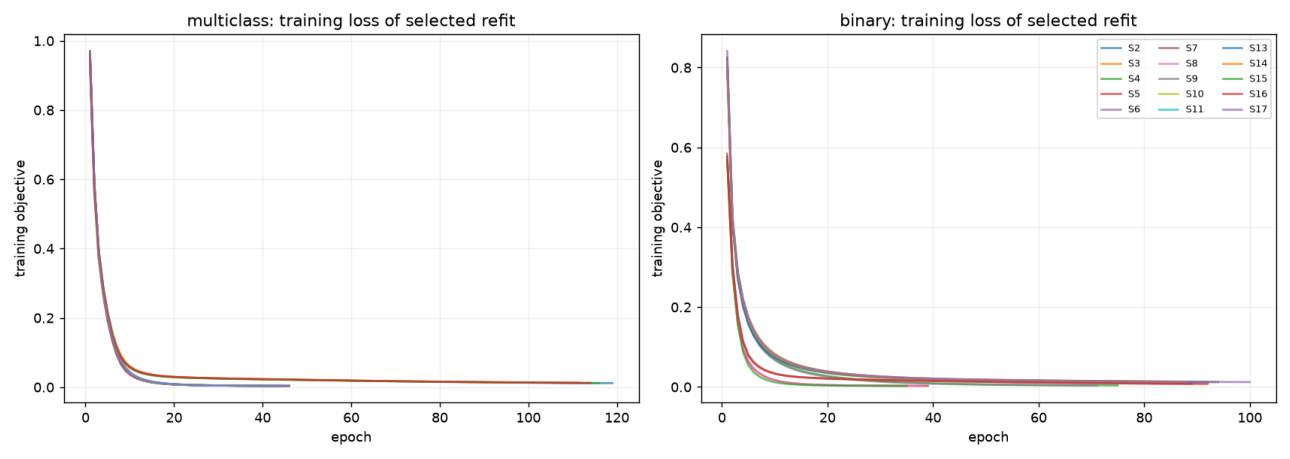

confusion_matrices.png


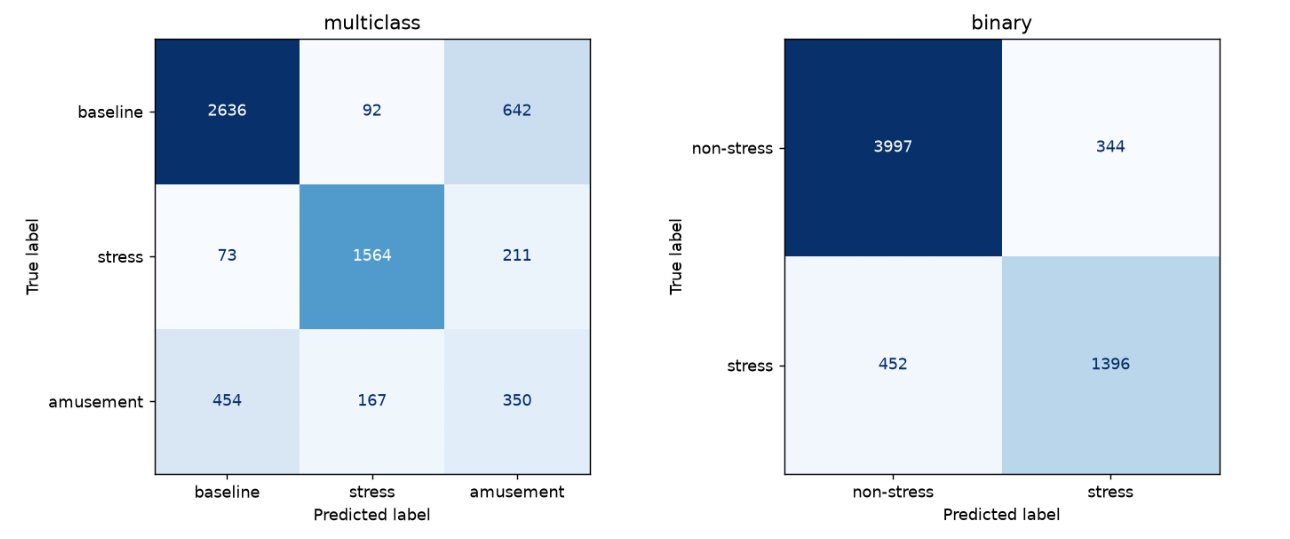

selected_candidates.png


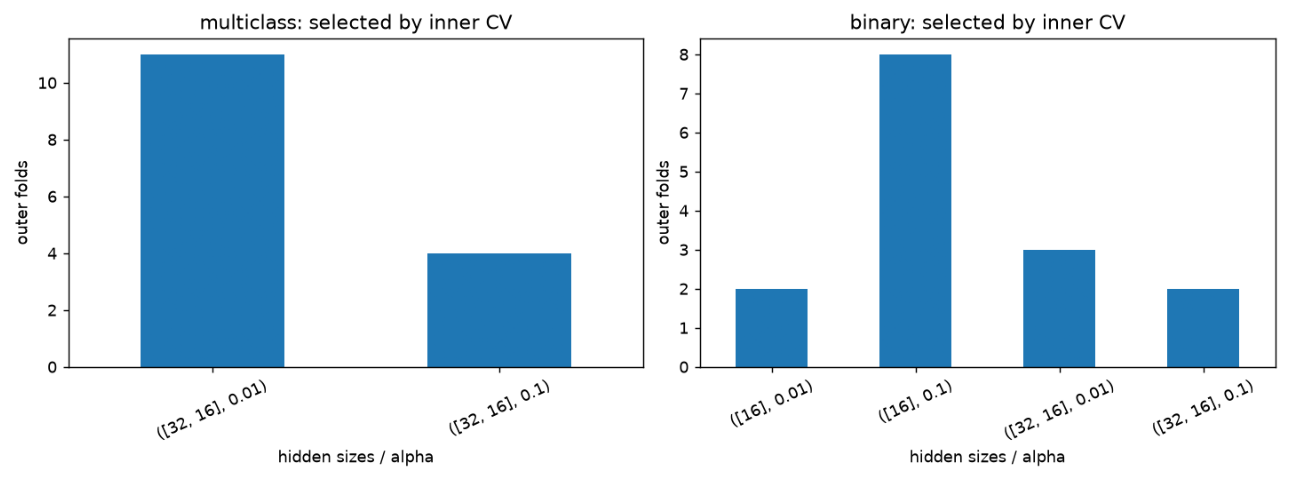

In [9]:
import matplotlib.pyplot as plt
for name in ['exp010_vs_exp020.png','train_vs_test.png','train_loss.png','confusion_matrices.png','selected_candidates.png']:
    path=run/'figures'/name
    print(name)
    image=plt.imread(path)
    fig,ax=plt.subplots(figsize=(13,8))
    ax.imshow(image);ax.axis('off');fig.tight_layout();plt.show()


## 09 — phân tích và giới hạn


In [10]:

print();print('cảnh báo thực tế:')
convergence=pd.read_csv(run/'convergence.csv')
print(convergence[['task','subject_id','n_iter','reached_max_iter','warning_count','warnings']].fillna('').to_string(index=False))



cảnh báo thực tế:
      task subject_id  n_iter  reached_max_iter  warning_count warnings
multiclass         S2      44             False              0         
multiclass         S3      44             False              0         
multiclass         S4      44             False              0         
multiclass         S5      44             False              0         
multiclass         S6      46             False              0         
multiclass         S7      46             False              0         
multiclass         S8      44             False              0         
multiclass         S9      45             False              0         
multiclass        S10      44             False              0         
multiclass        S11      45             False              0         
multiclass        S13     119             False              0         
multiclass        S14     111             False              0         
multiclass        S15     116             Fal

C:\Users\LEGION\AppData\Local\Temp\ipykernel_41772\1260653295.py:3: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  print(convergence[['task','subject_id','n_iter','reached_max_iter','warning_count','warnings']].fillna('').to_string(index=False))


## nhận xét exp020 (19/11)

Mục tiêu là để thử kiến trúc MLP nhỏ hơn và tăng alpha để khảo sát khả năng tổng quát hóa

Nhị phân: Macro-F1 đạt 0,8164, tăng 0,0345 so với EXP-010

Ba lớp: Macro-F1 đạt 0,6211, tăng nhẹ 0,0024 so với EXP-010

Khác biệt giữa người: Nhị phân có 10 người tăng điểm, 3 người giảm và 2 người không đổi, 3 lớp có 9 người tăng và 6 người giảm

Train và test: Macro-F1 trên train đạt 1,0000, nhưng test thấp hơn đáng kể cho thấy mô hình vẫn còn hạn chế khi dự đoán người chưa gặp

Hội tụ: Kết quả đã lưu không ghi nhận cảnh báo; cả 30 outer refits đều dừng trước giới hạn 200 vòng

Chạy lại: Ba lượt cùng seed 42 cho dự đoán giống nhau, cho thấy khả năng tái lập trong cấu hình này


Kết luận: Lưới mới cải thiện rõ hơn ở bài toán nhị phân ,bài toán ba lớp chỉ tăng nhẹ => chưa đủ khẳng định là sẽ ổn định

Hướng tiếp theo: Thử các seed khác và chọn cấu hình bằng inner CV để kiểm tra độ ổn định

## 10 — kết luận và nhật ký minh chứng

19/11/2026 :

tạo và chạy grid mới

giữ R01 làm kết quả chính

chạy R02/R03 để kiểm tra cùng seed

lỗi thực tế khi khởi động hai lượt song song: FileExistsError (WinError 183) do tên thư mục timestamp trùng lượt đầu
hai lần khởi động này chưa train nên không tính là hai lượt thành công

chưa có khảo sát seed khác, grid rộng, kiểm định thống kê hoặc final holdout độc lập





In [8]:
print('provenance R01:')
print(json.dumps(read_json(run/'notebook_provenance.json'),ensure_ascii=False,indent=2))
print('kiểm tra tái lập:')
print(json.dumps(read_json(run/'repeatability_verification.json'),ensure_ascii=False,indent=2))
print('config:',run/'config.yaml')
print('snapshots:',run/'source_snapshot.zip',run/'report_source_snapshot.zip')
print('minh chứng lỗi:',package/'launch_history.md')


provenance R01:
{
  "experiment": "EXP-020",
  "member": "như",
  "date": "18/11/2026",
  "run_type": "new",
  "git_commit": "5fadb6418367c67919ec70ea04fc92f4b6066ecc",
  "git_dirty": true,
  "source_status": "uncommitted changes captured in source_snapshot.zip",
  "python_executable": "C:\\Users\\LEGION\\Desktop\\github\\Machine-learning\\wesad-stress-detection\\.venv-g1\\Scripts\\python.exe",
  "command": "C:\\Users\\LEGION\\Desktop\\github\\Machine-learning\\wesad-stress-detection\\.venv-g1\\Scripts\\python.exe scripts/exp020_train.py",
  "outer_folds": 30,
  "inner_fits": 360,
  "outer_refits": 30,
  "seed": 42,
  "reference_experiment": "EXP-010",
  "feature_sha256": "2f2fddd678f333a800f2869d2e78b407934b2c3492190ed70e28d8a9107fd8ba",
  "interpretation": "exploratory comparison on reused LOSO benchmark; no independent final holdout"
}
kiểm tra tái lập:
{
  "status": "passed",
  "independent_runs": 3,
  "outer_fits": 90,
  "inner_fits": 1080,
  "all_predictions_match": true,
  "inte

## bổ sung ngày 20/11 kiểm tra độ nhạy theo seed

 Seed 42 dùng kết quả chính đã có
 
 seed 43 và 44 được chạy nested CV mới, mỗi seed đủ 30 outer fold và 360 inner fits
 
 

In [1]:
from pathlib import Path
import pandas as pd, json, sys
root = next(p for p in [Path.cwd(), Path.cwd()/'wesad-stress-detection', *Path.cwd().parents] if (p/'src/wesad').is_dir())
folder=root/'experiments/04_additional/EXP-020/seed_sensitivity/20261120'
print('ngày tổng hợp: 20/11/2026')
print('python:',sys.executable)
summary=pd.read_csv(folder/'summary_by_seed.csv')
print(summary.to_string(index=False))

ngày tổng hợp: 20/11/2026
python: d:\venvs\wesad312\Scripts\python.exe
      task  seed  subjects  macro_f1_mean  macro_f1_sd_subjects  ba_mean  ba_sd_subjects  warnings  max_epoch_folds  epochs_mean
    binary    42        15       0.816369              0.175437 0.835633        0.164323         0                0    78.000000
    binary    43        15       0.792662              0.187874 0.817194        0.168814         0                0    64.600000
    binary    44        15       0.844645              0.139280 0.855423        0.135012         0                0    73.733333
multiclass    42        15       0.621062              0.114969 0.660917        0.103798         0                0    63.466667
multiclass    43        15       0.614526              0.147566 0.652948        0.135826         0                0    70.466667
multiclass    44        15       0.620265              0.116624 0.655334        0.106382         0                0    94.666667


Thanh sai số dưới đây là độ lệch chuẩn giữa 15 người tại từng seed

 

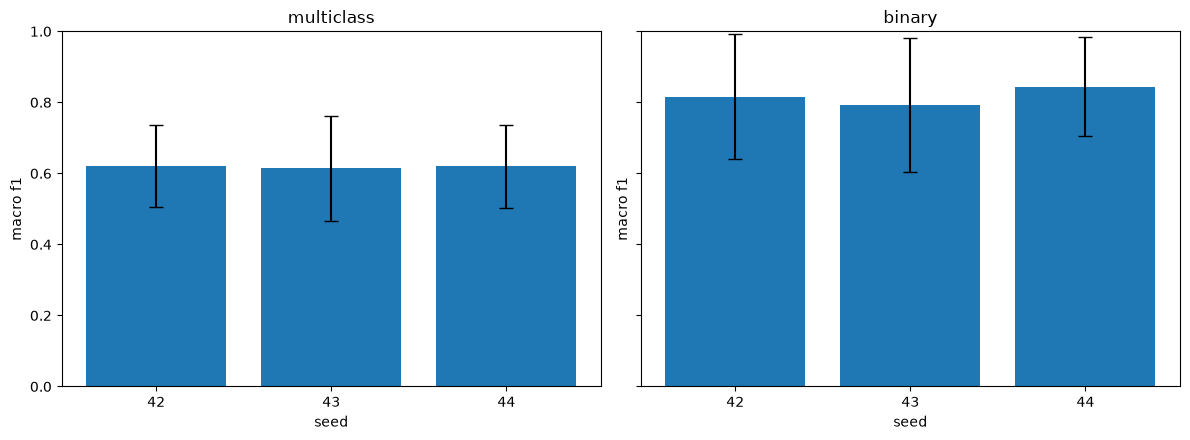

In [2]:
import matplotlib.pyplot as plt
summary=pd.read_csv(folder/'summary_by_seed.csv')
fig,axes=plt.subplots(1,2,figsize=(12,4.5),sharey=True)
for ax,task in zip(axes,['multiclass','binary']):
    g=summary[summary.task==task].sort_values('seed')
    ax.bar(g.seed.astype(str),g.macro_f1_mean,yerr=g.macro_f1_sd_subjects,capsize=5)
    ax.set(title=task,xlabel='seed',ylabel='macro f1',ylim=(0,1))
fig.tight_layout()

      task  seed_mean_f1  seed_sd_f1  min_seed_mean_f1  max_seed_mean_f1
    binary      0.817892    0.026025          0.792662          0.844645
multiclass      0.618618    0.003565          0.614526          0.621062
      task  seed  n_windows  prediction_agreement
    binary    43       6189              0.958636
multiclass    43       6189              0.831314
    binary    44       6189              0.957344
multiclass    44       6189              0.861529
số outer fold mới: 60


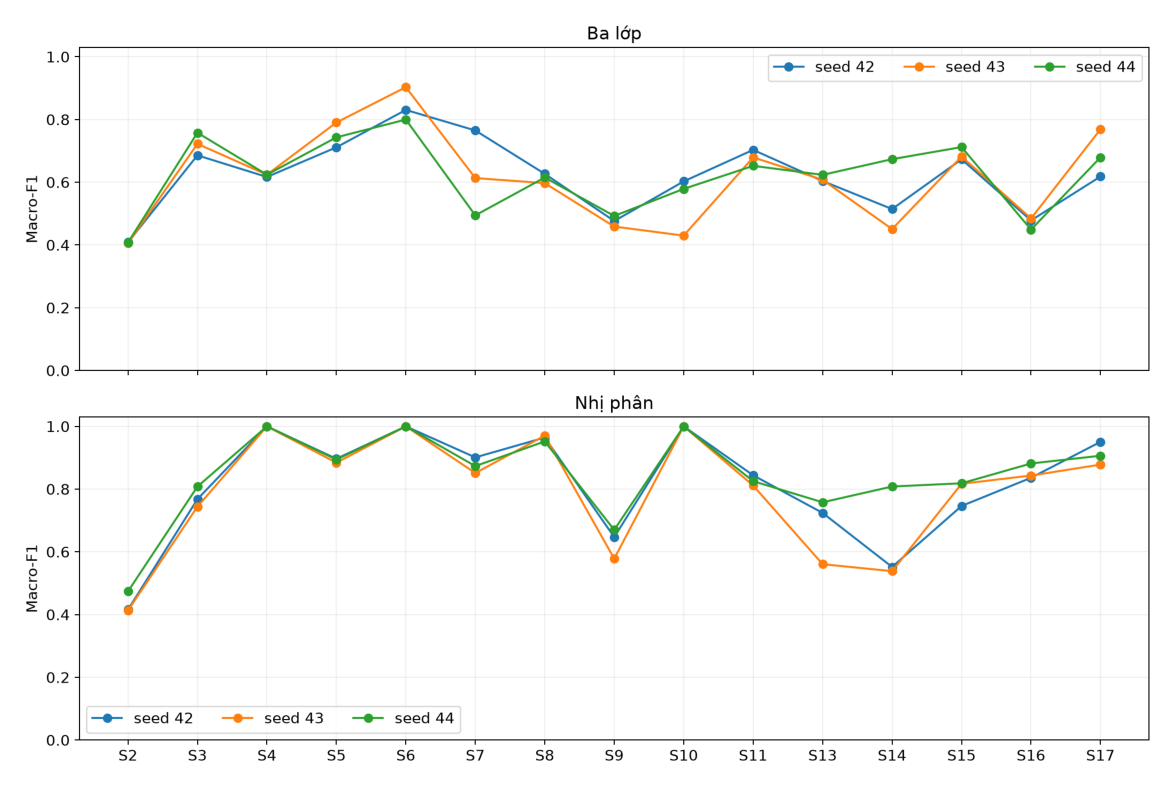

In [3]:
scores=pd.read_csv(folder/'scores_by_subject_seed.csv')
print(pd.read_csv(folder/'variability_across_seeds.csv').to_string(index=False))
print(pd.read_csv(folder/'prediction_agreement.csv').to_string(index=False))
print('số outer fold mới:',len(scores[scores.seed.isin([43,44])]))
fig=plt.figure(figsize=(12,8))
plt.imshow(plt.imread(folder/'figures/subject_scores_by_seed.png'))
plt.axis('off')
fig.tight_layout()

### nhận xét (20/11)

multiclass: Macro-F1 của seed 42/43/44 lần lượt là 0.6211 / 0.6145 / 0.6203

=> Khoảng biến động trung bình theo seed là 0.0065

binary: Macro-F1 của seed 42/43/44 lần lượt là 0.8164 / 0.7927 / 0.8446

=>Khoảng biến động trung bình theo seed là 0.0520

Điểm theo seed được tính từ cùng 15 người

 Đây là kiểm tra độ nhạy của cả quá trình chọn tham số và huấn luyện MLP